## Student Details
- **Name:** Parth Kitchloo
- **PRN:** 202401110014
- **Branch:** Artificial Intelligence and Machine Learning (AIML)
- **Batch:** A2


# Practical No. 05: Image Generation using Pretrained Stable Diffusion
**Course practical | Google Colab | Hugging Face Diffusers**

## Aim
Implement a pretrained Stable Diffusion text-to-image model and study how inference steps, classifier-free guidance scale, and scheduler/sampling method affect generated image quality and runtime.

## Learning objectives
1. Load a pretrained Stable Diffusion pipeline with Hugging Face Diffusers.
2. Generate images from carefully designed prompts and negative prompts.
3. Compare inference-step counts while keeping other settings fixed.
4. Compare guidance scales and scheduler choices using a fixed seed.
5. Record observations, timings, and limitations.

## How to run
1. Open this notebook in Google Colab.
2. Select **Runtime → Change runtime type → T4 GPU** (or another GPU), then save.
3. Run cells from top to bottom. The first model download can take several minutes.
4. If you are on CPU, generation will be much slower. If the model download requests Hugging Face access, sign in to Hugging Face, accept the model's license on its model page, and add a token through Colab Secrets; never paste a token into a notebook shared publicly.
5. Keep the same prompt and seed during each comparison. The notebook saves generated images under `stable_diffusion_outputs/`.

**Reproducibility note:** the seed controls the initial random noise, but different schedulers may still produce different images. Results and timings can vary by GPU, library version, and runtime load.

## 1. Install required libraries
Run this cell once per fresh Colab runtime. It upgrades the Diffusers stack without uninstalling PyTorch, which can prevent unnecessary dependency conflicts.

In [1]:
%pip install -q -U diffusers transformers accelerate safetensors matplotlib "pandas==2.2.3"

## 2. Imports and device configuration

In [2]:
import os, time, gc, json
import pandas as pd
import matplotlib.pyplot as plt
import torch
from diffusers import (
    StableDiffusionPipeline,
    PNDMScheduler,
    DDIMScheduler,
    EulerDiscreteScheduler,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler,
)

SEED = 42
OUTPUT_DIR = "stable_diffusion_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print(f"Device: {device} | dtype: {dtype}")
if device == "cpu":
    print("Note: CPU inference is supported but may be very slow. A Colab GPU is recommended.")

Device: cuda | dtype: torch.float16


## 3. Load the pretrained Stable Diffusion model
The pipeline combines the main model components:
- **Tokenizer and text encoder:** convert the text prompt into embeddings.
- **U-Net denoiser:** predicts noise at each denoising step, conditioned on the text embeddings.
- **Scheduler:** controls how the latent is updated at each step.
- **VAE (variational autoencoder):** decodes the final latent representation into an image.

Stable Diffusion starts from random latent noise and progressively denoises it under text conditioning. The pipeline handles the component interactions.

In [3]:
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

try:
    pipe = StableDiffusionPipeline.from_pretrained(
        MODEL_ID,
        torch_dtype=dtype,
        use_safetensors=True,
    )
    pipe = pipe.to(device)
    # Reduce peak memory use on supported environments.
    if device == "cuda":
        pipe.enable_attention_slicing()
    scheduler_config = pipe.scheduler.config
    print("Model loaded successfully:", MODEL_ID)
    print("Scheduler initially loaded:", pipe.scheduler.__class__.__name__)
except Exception as e:
    raise RuntimeError(
        "Model loading failed. Check internet access, available GPU/RAM, and whether "
        "the Hugging Face model license/access is required for your account. "
        "If access is required, accept the license on the model page and authenticate "
        "securely through Colab Secrets. Original error: " + repr(e)
    )

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Model loaded successfully: stable-diffusion-v1-5/stable-diffusion-v1-5
Scheduler initially loaded: PNDMScheduler


## 4. Helper functions
A fixed seed makes comparisons more controlled. The negative prompt describes features to avoid; it is a guidance aid, not a guarantee.

In [4]:
def generate_image(prompt, negative_prompt="", steps=30, guidance=7.5, seed=SEED):
    # Use a generator on the same device as inference.
    generator = torch.Generator(device=device).manual_seed(int(seed))
    start = time.perf_counter()
    with torch.inference_mode():
        result = pipe(
            prompt=prompt,
            negative_prompt=negative_prompt or None,
            num_inference_steps=int(steps),
            guidance_scale=float(guidance),
            generator=generator,
        )
    elapsed = time.perf_counter() - start
    return result.images[0], elapsed

def show_images(images, titles, columns=3, figsize_per_image=4):
    if not images:
        print("No images to display.")
        return
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(figsize_per_image*columns, figsize_per_image*rows))
    axes = list(getattr(axes, "flat", [axes]))
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    for ax in axes[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def save_image(image, filename):
    path = os.path.join(OUTPUT_DIR, filename)
    image.save(path)
    print("Saved:", path)
    return path

## 5. Experiment A — baseline text-to-image generation
Prompt engineering tip: include a clear subject, setting, style, lighting, and composition. Avoid excessively long lists of conflicting styles.

  0%|          | 0/30 [00:00<?, ?it/s]

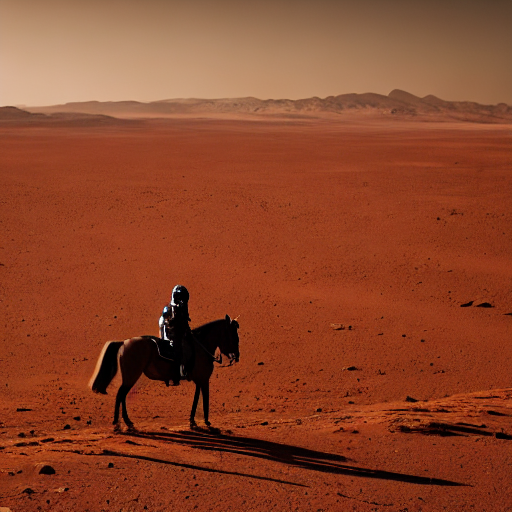

Baseline generation time: 8.96 seconds
Saved: stable_diffusion_outputs/baseline.png


'stable_diffusion_outputs/baseline.png'

In [5]:
prompt = (
    "A cinematic photograph of an astronaut riding a horse on Mars, "
    "rust-red desert, distant mountains, dramatic golden-hour lighting, "
    "high detail, balanced composition, realistic photography"
)
negative_prompt = "blurry, low quality, distorted anatomy, extra limbs, text, watermark, oversaturated"

baseline_image, baseline_seconds = generate_image(
    prompt, negative_prompt=negative_prompt, steps=30, guidance=7.5, seed=SEED
)
display(baseline_image)
print(f"Baseline generation time: {baseline_seconds:.2f} seconds")
save_image(baseline_image, "baseline.png")

## 6. Experiment B — effect of inference steps
**Independent variable:** number of inference steps.  
**Kept constant:** prompt, negative prompt, guidance scale, scheduler, and seed.

More steps allow more denoising updates, but increase runtime. Improvement is not guaranteed to be linear, and very high step counts can give diminishing returns.

  0%|          | 0/5 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/steps_5.png


  0%|          | 0/10 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/steps_10.png


  0%|          | 0/20 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/steps_20.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/steps_30.png


  0%|          | 0/50 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/steps_50.png


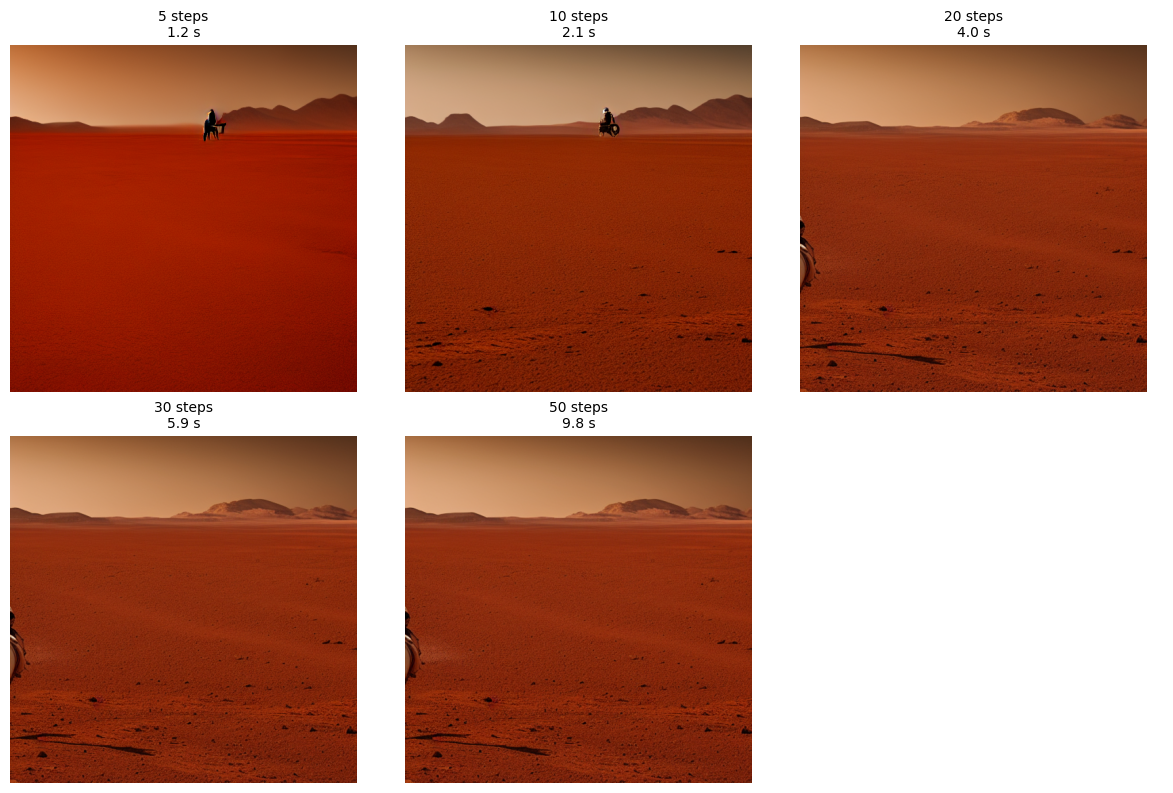

,Experiment,Steps,Guidance scale,Scheduler,Time (seconds)
0,Inference steps,5,7.5,DPMSolverMultistep,1.20
1,Inference steps,10,7.5,DPMSolverMultistep,2.12
2,Inference steps,20,7.5,DPMSolverMultistep,4.01
3,Inference steps,30,7.5,DPMSolverMultistep,5.92
4,Inference steps,50,7.5,DPMSolverMultistep,9.75


In [6]:
pipe.scheduler = DPMSolverMultistepScheduler.from_config(scheduler_config)
step_values = [5, 10, 20, 30, 50]
step_images, step_titles, step_rows = [], [], []

for n_steps in step_values:
    img, elapsed = generate_image(
        prompt, negative_prompt=negative_prompt, steps=n_steps, guidance=7.5, seed=SEED
    )
    step_images.append(img)
    step_titles.append(f"{n_steps} steps\n{elapsed:.1f} s")
    step_rows.append({"Experiment": "Inference steps", "Steps": n_steps,
                      "Guidance scale": 7.5, "Scheduler": "DPMSolverMultistep",
                      "Time (seconds)": round(elapsed, 2)})
    save_image(img, f"steps_{n_steps}.png")

show_images(step_images, step_titles, columns=3)
step_results = pd.DataFrame(step_rows)
display(step_results)

### Analysis — inference steps

Use the generated comparison grid and measured runtime table above. The following table summarizes the expected trade-off; verify the visual-quality column against your own images before submission.

In [7]:
step_analysis = pd.DataFrame([
    {"Steps": n,
     "Runtime interpretation": (
         "Lowest expected runtime; inspect whether details look under-refined." if n == 5 else
         "Usually faster than higher-step settings; compare subject clarity." if n == 10 else
         "Moderate compute cost; compare detail and composition." if n == 20 else
         "Reference setting for the other experiments." if n == 30 else
         "Highest expected runtime among tested settings; check whether added detail justifies the cost."
     ),
     "Visual observation to record": "Compare sharpness, composition, artifacts, and prompt match in the generated grid."}
    for n in step_values
])
display(step_analysis)
print("Measured runtime trend (seconds):")
display(step_results[["Steps", "Time (seconds)"]].sort_values("Steps"))

,Steps,Runtime interpretation,Visual observation to record
0,5,Lowest expected runtime; inspect whether detai...,"Compare sharpness, composition, artifacts, and..."
1,10,Usually faster than higher-step settings; comp...,"Compare sharpness, composition, artifacts, and..."
2,20,Moderate compute cost; compare detail and comp...,"Compare sharpness, composition, artifacts, and..."
3,30,Reference setting for the other experiments.,"Compare sharpness, composition, artifacts, and..."
4,50,Highest expected runtime among tested settings...,"Compare sharpness, composition, artifacts, and..."


Measured runtime trend (seconds):


,Steps,Time (seconds)
0,5,1.20
1,10,2.12
2,20,4.01
3,30,5.92
4,50,9.75


## 7. Experiment C — effect of classifier-free guidance scale
**Independent variable:** guidance scale.  
**Kept constant:** prompt, negative prompt, steps, scheduler, and seed.

Guidance scale controls how strongly generation is steered toward the prompt. A low value may follow the prompt less closely; a very high value can produce harsh contrast, oversaturation, or artifacts. The best value depends on the prompt and model.

  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/guidance_1_0.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/guidance_3_0.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/guidance_7_5.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/guidance_12_0.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/guidance_15_0.png


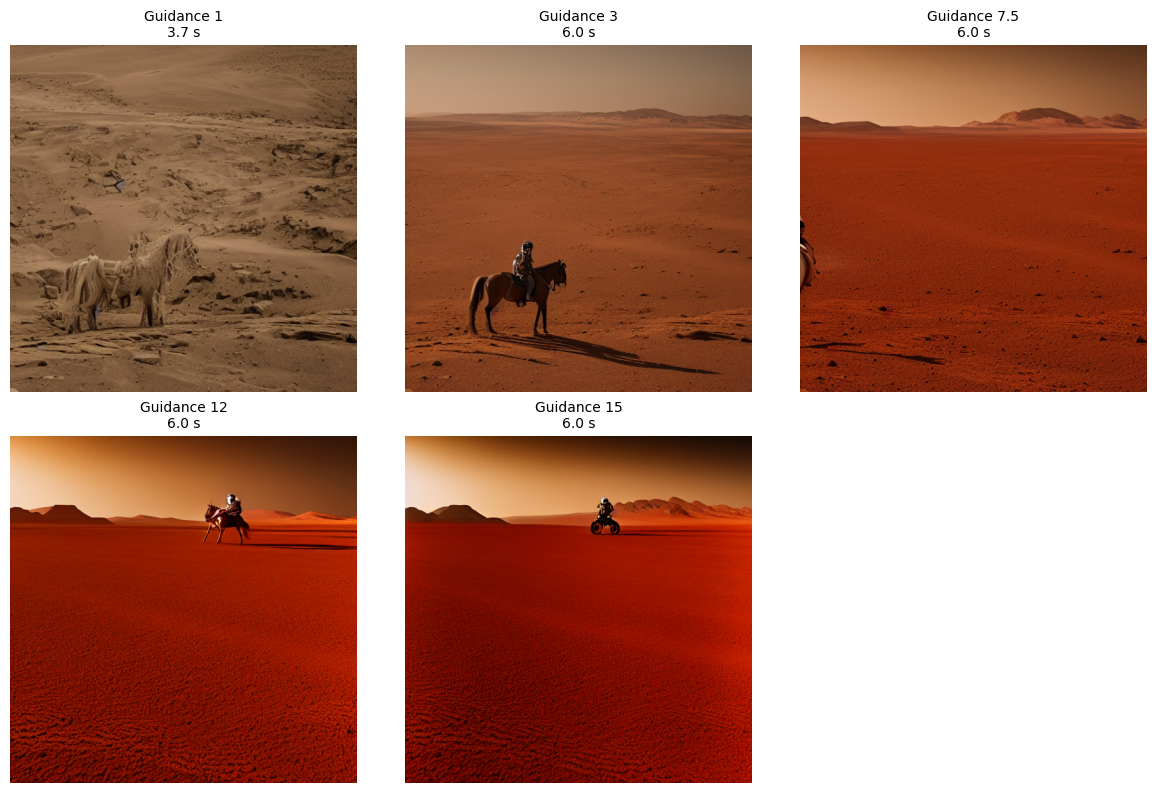

,Experiment,Steps,Guidance scale,Scheduler,Time (seconds)
0,Guidance scale,30,1.0,DPMSolverMultistep,3.73
1,Guidance scale,30,3.0,DPMSolverMultistep,5.97
2,Guidance scale,30,7.5,DPMSolverMultistep,5.97
3,Guidance scale,30,12.0,DPMSolverMultistep,6.00
4,Guidance scale,30,15.0,DPMSolverMultistep,6.02


In [8]:
pipe.scheduler = DPMSolverMultistepScheduler.from_config(scheduler_config)
guidance_values = [1.0, 3.0, 7.5, 12.0, 15.0]
guidance_images, guidance_titles, guidance_rows = [], [], []

for scale in guidance_values:
    img, elapsed = generate_image(
        prompt, negative_prompt=negative_prompt, steps=30, guidance=scale, seed=SEED
    )
    guidance_images.append(img)
    guidance_titles.append(f"Guidance {scale:g}\n{elapsed:.1f} s")
    guidance_rows.append({"Experiment": "Guidance scale", "Steps": 30,
                          "Guidance scale": scale, "Scheduler": "DPMSolverMultistep",
                          "Time (seconds)": round(elapsed, 2)})
    save_image(img, f"guidance_{str(scale).replace('.', '_')}.png")

show_images(guidance_images, guidance_titles, columns=3)
guidance_results = pd.DataFrame(guidance_rows)
display(guidance_results)

### Analysis — guidance scale

Guidance scale is a trade-off between prompt conditioning and visual naturalness. Use the images above to determine which value worked best for this prompt; high guidance is not automatically better.

In [9]:
guidance_analysis = pd.DataFrame([
    {"Guidance scale": g,
     "What to inspect": (
         "Weak prompt conditioning may be noticeable; verify in the image." if g == 1.0 else
         "Check whether the subject and setting follow the prompt." if g == 3.0 else
         "Moderate reference value; assess prompt match and natural appearance." if g == 7.5 else
         "Inspect for stronger contrast, oversaturation, or artifacts." if g == 12.0 else
         "High guidance: carefully inspect for harsh contrast or unnatural details."
     ),
     "Observed result": "Record your own visual assessment after comparing the grid."}
    for g in guidance_values
])
display(guidance_analysis)

,Guidance scale,What to inspect,Observed result
0,1.0,Weak prompt conditioning may be noticeable; ve...,Record your own visual assessment after compar...
1,3.0,Check whether the subject and setting follow t...,Record your own visual assessment after compar...
2,7.5,Moderate reference value; assess prompt match ...,Record your own visual assessment after compar...
3,12.0,"Inspect for stronger contrast, oversaturation,...",Record your own visual assessment after compar...
4,15.0,High guidance: carefully inspect for harsh con...,Record your own visual assessment after compar...


## 8. Experiment D — compare schedulers (sampling methods)
**Independent variable:** scheduler.  
**Kept constant:** prompt, negative prompt, steps, guidance scale, and seed.

Schedulers use different numerical update rules for the denoising process. Euler Ancestral includes stochasticity during sampling, so it may vary differently from deterministic methods even when the initial seed is fixed. Timings are environment-dependent.

  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/scheduler_pndm.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/scheduler_ddim.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/scheduler_euler.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/scheduler_euler_ancestral.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/scheduler_dpm_solverplusplus_2m.png


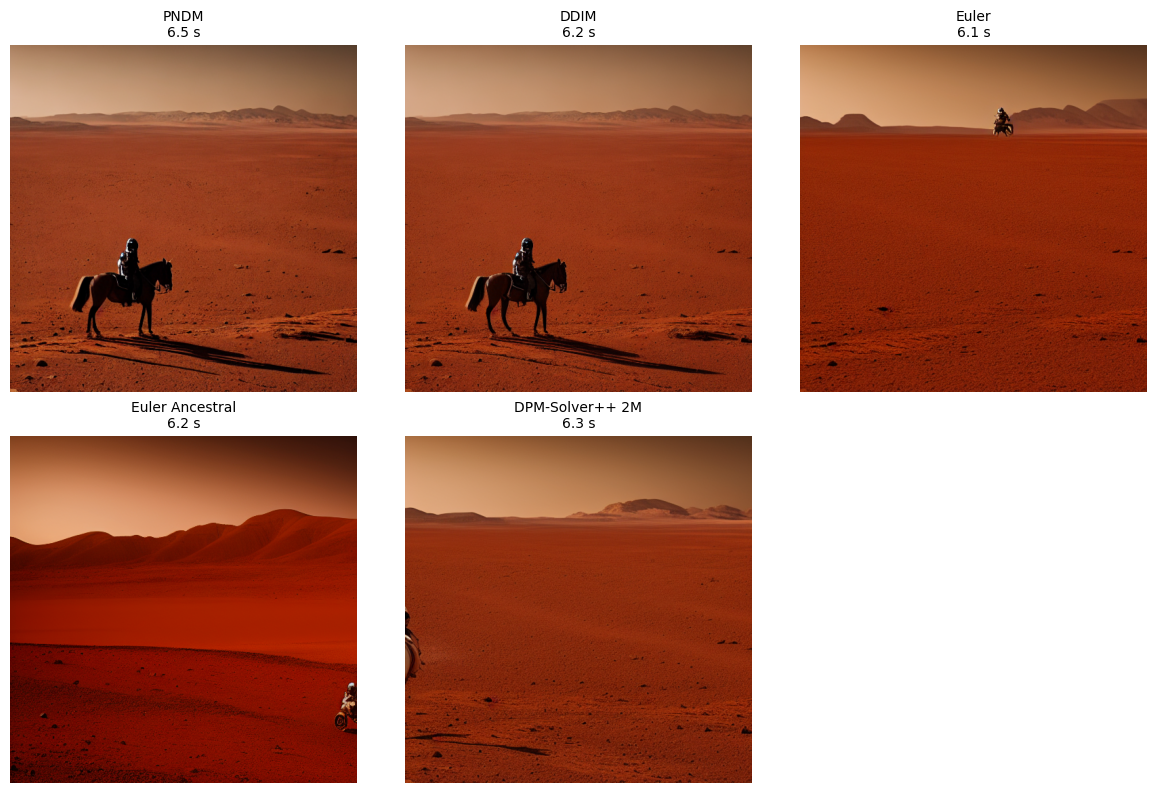

,Scheduler,Steps,Guidance scale,Time (seconds)
0,PNDM,30,7.5,6.45
1,DDIM,30,7.5,6.15
2,Euler,30,7.5,6.13
3,Euler Ancestral,30,7.5,6.19
4,DPM-Solver++ 2M,30,7.5,6.26


In [10]:
scheduler_classes = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler Ancestral": EulerAncestralDiscreteScheduler,
    "DPM-Solver++ 2M": DPMSolverMultistepScheduler,
}
scheduler_images, scheduler_titles, scheduler_rows = [], [], []

for name, scheduler_class in scheduler_classes.items():
    pipe.scheduler = scheduler_class.from_config(scheduler_config)
    img, elapsed = generate_image(
        prompt, negative_prompt=negative_prompt, steps=30, guidance=7.5, seed=SEED
    )
    scheduler_images.append(img)
    scheduler_titles.append(f"{name}\n{elapsed:.1f} s")
    scheduler_rows.append({"Scheduler": name, "Steps": 30, "Guidance scale": 7.5,
                           "Time (seconds)": round(elapsed, 2)})
    safe_name = name.lower().replace(" ", "_").replace("+", "plus").replace("-", "_")
    save_image(img, f"scheduler_{safe_name}.png")

show_images(scheduler_images, scheduler_titles, columns=3)
scheduler_results = pd.DataFrame(scheduler_rows)
display(scheduler_results)

### Analysis — scheduler comparison

Schedulers use different numerical update rules. Compare the actual outputs at the same prompt, seed, step count, and guidance scale. Report a winner only for this experiment; performance can change with prompts and settings.

In [11]:
scheduler_analysis = pd.DataFrame([
    {"Scheduler": name,
     "Comparison criteria": "Prompt adherence, composition, sharpness, artifacts, and measured runtime.",
     "Observed result": "Record what you see in the scheduler comparison grid."}
    for name in scheduler_classes.keys()
])
display(scheduler_analysis)
display(scheduler_results.sort_values("Time (seconds)"))

,Scheduler,Comparison criteria,Observed result
0,PNDM,"Prompt adherence, composition, sharpness, arti...",Record what you see in the scheduler compariso...
1,DDIM,"Prompt adherence, composition, sharpness, arti...",Record what you see in the scheduler compariso...
2,Euler,"Prompt adherence, composition, sharpness, arti...",Record what you see in the scheduler compariso...
3,Euler Ancestral,"Prompt adherence, composition, sharpness, arti...",Record what you see in the scheduler compariso...
4,DPM-Solver++ 2M,"Prompt adherence, composition, sharpness, arti...",Record what you see in the scheduler compariso...


,Scheduler,Steps,Guidance scale,Time (seconds)
2,Euler,30,7.5,6.13
1,DDIM,30,7.5,6.15
3,Euler Ancestral,30,7.5,6.19
4,DPM-Solver++ 2M,30,7.5,6.26
0,PNDM,30,7.5,6.45


## 9. Experiment E — prompt engineering and negative prompts
This small additional experiment compares a concise prompt, a more descriptive prompt, and a negative prompt. The model and generation parameters remain the same.

  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/prompt_short_prompt.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/prompt_detailed_prompt.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: stable_diffusion_outputs/prompt_detailed_plus_negative.png


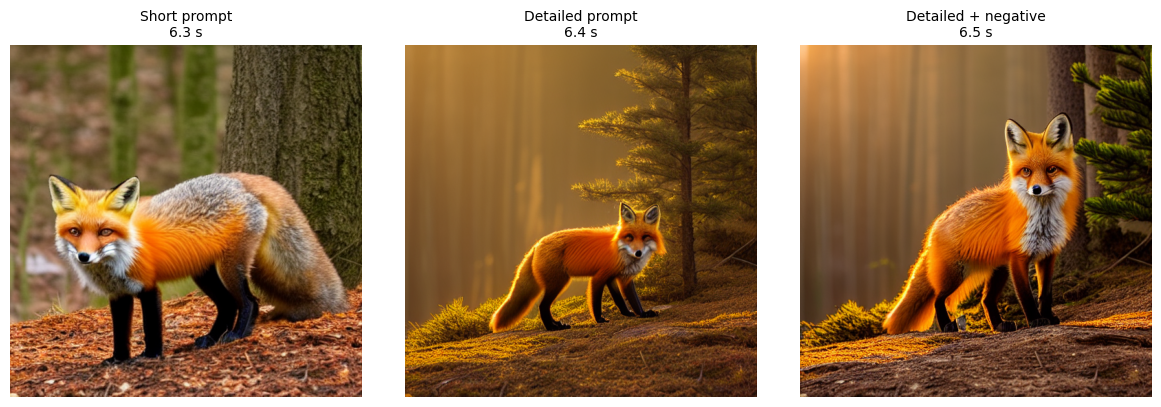

In [12]:
prompt_variants = [
    ("Short prompt", "a red fox in a forest"),
    ("Detailed prompt", "A red fox standing in a misty pine forest at sunrise, soft golden rim light, natural colors, wildlife photography, sharp focus"),
    ("Detailed + negative", "A red fox standing in a misty pine forest at sunrise, soft golden rim light, natural colors, wildlife photography, sharp focus"),
]
variant_negative = ["", "", "blurry, low quality, cartoon, text, watermark, distorted"]
variant_images, variant_titles = [], []

pipe.scheduler = DPMSolverMultistepScheduler.from_config(scheduler_config)
for (label, p), neg in zip(prompt_variants, variant_negative):
    img, elapsed = generate_image(p, negative_prompt=neg, steps=30, guidance=7.5, seed=SEED)
    variant_images.append(img)
    variant_titles.append(f"{label}\n{elapsed:.1f} s")
    save_image(img, "prompt_" + label.lower().replace(" ", "_").replace("+", "plus") + ".png")

show_images(variant_images, variant_titles, columns=3)

## 10. Consolidated results and export

The following table combines measured generation times for inference-step, guidance-scale, and scheduler experiments. The notebook also saves generated images in `stable_diffusion_outputs/`. Review the comparison grids and complete the brief visual assessments in Sections 6–8 before submission.

In [13]:
all_results = pd.concat([step_results, guidance_results, scheduler_results], ignore_index=True)
display(all_results)
csv_path = os.path.join(OUTPUT_DIR, "measured_results.csv")
all_results.to_csv(csv_path, index=False)
print("Saved results table:", csv_path)

,Experiment,Steps,Guidance scale,Scheduler,Time (seconds)
0,Inference steps,5,7.5,DPMSolverMultistep,1.20
1,Inference steps,10,7.5,DPMSolverMultistep,2.12
2,Inference steps,20,7.5,DPMSolverMultistep,4.01
3,Inference steps,30,7.5,DPMSolverMultistep,5.92
4,Inference steps,50,7.5,DPMSolverMultistep,9.75
5,Guidance scale,30,1.0,DPMSolverMultistep,3.73
6,Guidance scale,30,3.0,DPMSolverMultistep,5.97
7,Guidance scale,30,7.5,DPMSolverMultistep,5.97
8,Guidance scale,30,12.0,DPMSolverMultistep,6.00
9,Guidance scale,30,15.0,DPMSolverMultistep,6.02


Saved results table: stable_diffusion_outputs/measured_results.csv


In [14]:
# Optional: package generated images and the measured results as one ZIP file.
import shutil
zip_path = shutil.make_archive("stable_diffusion_outputs", "zip", OUTPUT_DIR)
print("Created archive:", zip_path)

Created archive: /content/stable_diffusion_outputs.zip


## 11. Analysis and conclusion

Use the measured tables and the images generated in this run to finalize the conclusion. Do not report a visual winner unless the images support it.

### Discussion
- **Inference steps:** More inference steps mean more denoising updates and generally increase runtime. The image grid lets you judge whether added steps improved detail enough to justify the extra time. Improvement may diminish at higher step counts.
- **Guidance scale:** A low value may give weaker prompt adherence. Moderate guidance can balance adherence and natural appearance, while very high guidance may introduce harsh contrast, oversaturation, or artifacts. The best value is prompt-dependent.
- **Schedulers:** PNDM, DDIM, Euler, Euler Ancestral, and DPM-Solver++ use different update rules. They can produce different denoising trajectories, visual details, and runtimes. There is no universally best scheduler for every prompt.
- **Prompt engineering:** A descriptive prompt specifying subject, setting, lighting, and style gives clearer direction. A negative prompt can discourage unwanted features but cannot guarantee their removal.
- **Reproducibility:** The same seed controls the initial random noise for more controlled comparisons. Different schedulers can still produce different outputs. Runtime varies by hardware and Colab load.

### Conclusion — personalize using your results
This practical implemented a pretrained Stable Diffusion text-to-image pipeline using Hugging Face Diffusers. The experiments varied inference steps, classifier-free guidance scale, and scheduler while keeping other settings fixed where possible. The generated comparison grids and runtime table show the trade-off between computational cost and output characteristics. The preferred settings should be selected from the actual outputs produced in this run, since image quality depends on prompt, seed, scheduler, and hardware.

### Limitations
This is a qualitative comparison using a small number of prompts and a fixed seed. Visual quality is judged by inspection rather than a formal image-quality metric. Runtime measurements can vary between runs and devices. A different prompt or seed may change the relative results.